# Week 10  Group Programming Challenge Four-Format Data Recovery and Validation

**Group 7 Final report**

One country dataset with life expectancy, population and GDP per capita was supplied in the DSA4153_Week10_Group_Task_Inputs.zip 
as CSV, Excel, JSON, and Parquet. Each file contains the same data behind different column names, layouts, and faults.
The report shows how the program creates a clean dataset from all four, proves that the agree, produces the pandas and NumPy, verify 
the exports, and refuse to publish anything if a run fails.



Every number below is produced by running the pipeline when this notebook is executed. nothing is typed in by hand.

## 1. Run the pipeline

In [1]:
import json, hashlib, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

sys.path.insert(0, ".")
from src.pipeline import ProcessingRun, ProcessingFailure, CATEGORIES

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_colwidth = 70

run = ProcessingRun("config.json")
summary = run.run()
OUT = Path(summary["published_to"])
year = summary["reporting_year"]
print(f"Run finished. Outputs published to: {OUT.name}/")

Run finished. Outputs published to: outputs/


## 2. Headline results

In [2]:
headline = pd.DataFrame([
    ("Raw rows read (per file)", f"{summary['files']['country_records.csv']['raw']:,}"),
    ("Canonical rows after cleaning", f"{summary['canonical_rows']:,}"),
    ("Countries", summary["countries"]),
    ("Rows quarantined (all four files)", summary["total_quarantined"]),
    ("Exact duplicates removed (all four files)", summary["total_duplicates_removed"]),
    (f"Asia {year}: countries", summary[f"asia_{year}_rows"]),
    (f"Asia {year}: total population", f"{summary[f'asia_{year}_population']:,}"),
    (f"Philippines {year}: population", f"{summary[f'philippines_{year}_population']:,}"),
    ("Validation checks passed", f"{summary['checks_passed']} / {summary['checks_total']}"),
], columns=["Measure", "Value"])
headline.style.hide(axis="index")

Measure,Value
Raw rows read (per file),"1,712"
Canonical rows after cleaning,"1,704"
Countries,142
Rows quarantined (all four files),24
Exact duplicates removed (all four files),8
Asia 2007: countries,33
Asia 2007: total population,"3,811,953,827"
Philippines 2007: population,"91,077,287"
Validation checks passed,58 / 58


## 3. Recovering the data from each format

each file is read as a text first, so nothing will be converted at the moment. Then its columns are renamed to the canonical names 
using manifest. The reader check the file's size and SHA-256 hash before trusting. Each row then goes through the validation rules.
Any row that breaks a rule are quarantined with a reason. Rows that repeat an earlier identical row are removed as duplicates. 
The rest become the cannonical table.

For every file the rows must reconcile: raw = quarantined + duplicates + canonical


In [3]:
rows = []
for name, c in summary["files"].items():
    rows.append({"File": name, "Raw": c["raw"], "Quarantined": c["rejected"],
                 "Duplicates removed": c["duplicates"], "Canonical": c["canonical"],
                 "Reconciles": c["raw"] == c["rejected"] + c["duplicates"] + c["canonical"]})
recon = pd.DataFrame(rows)
recon.style.hide(axis="index").format({"Raw": "{:,}", "Canonical": "{:,}"})

File,Raw,Quarantined,Duplicates removed,Canonical,Reconciles
country_records.csv,"1,712",6,2,"1,704",True
country_records.xlsx,"1,712",6,2,"1,704",True
country_records.json,"1,712",6,2,"1,704",True
country_records.parquet,"1,712",6,2,"1,704",True


### What was quarantined and why

In [4]:
q = pd.read_csv(OUT / "quarantine.csv", keep_default_na=False)
by_reason = (q.groupby("reason").size().rename("rows (all four files)").reset_index()
               .sort_values("rows (all four files)", ascending=False))
display(by_reason.style.hide(axis="index"))
print()
print("Quarantined rows from one file (the other three show the same faults):")
q[q["source_file"] == "country_records.csv"][["source_record", "reason", "country", "year", "lifeExp", "pop"]]

reason,rows (all four files)
fractional pop,4
invalid gdpPercap,4
invalid year,4
lifeExp out of range,4
missing country,4
pop must be positive,4



Quarantined rows from one file (the other three show the same faults):


,source_record,reason,country,year,lifeExp,pop
0,77,fractional pop,Albania,2007,76.42,100.50
1,232,invalid year,Albania,not-a-year,72.95,"3,428,038.00"
2,377,lifeExp out of range,Algeria,1952,150.00,"9,279,525.00"
3,647,pop must be positive,Albania,2002,75.65,-1.00
4,973,invalid gdpPercap,Algeria,1957,45.69,"10,270,856.00"
5,1176,missing country,,1992,71.58,"3,326,498.00"


### Duplicates removed

In [5]:
d = pd.read_csv(OUT / "duplicates_removed.csv")
d[d["source_file"] == "country_records.csv"][["source_record", "duplicate_of_record", "country", "year", "pop"]]

,source_record,duplicate_of_record,country,year,pop
0,979,662,Bangladesh,1972,70759295
1,1236,487,Afghanistan,1977,14880372


## 4. Do the four formats agree?
The recovered tables are compared by key (country and year), not by row position. Because each file lists its rows
in a different order and the CSV table is the reference. Floats must match to within 1e-9.

In [6]:
cmp_ = pd.read_csv(OUT / "format_comparison.csv")
cmp_.style.hide(axis="index").format({"rows_reference": "{:,}", "rows_compared": "{:,}"})

reference,compared,rows_reference,rows_compared,only_in_reference,only_in_compared,value_mismatches,agree
country_records.csv,country_records.xlsx,"1,704","1,704",0,0,0,True
country_records.csv,country_records.json,"1,704","1,704",0,0,0,True
country_records.csv,country_records.parquet,"1,704","1,704",0,0,0,True


In [7]:
assert cmp_["agree"].all()
display(Markdown(f"All {len(cmp_)} comparisons agree: no missing rows, no extra rows and no value differences "
                 f"across the four formats, so one canonical table of **{summary['canonical_rows']:,}** rows is trusted."))

All 3 comparisons agree: no missing rows, no extra rows and no value differences across the four formats, so one canonical table of **1,704** rows is trusted.

## 5. Analysis results
###  Pandas - Asia in the reporting year

In [8]:
asia = pd.read_csv(OUT / "asia_selected_year.csv")
display(Markdown(f"**{len(asia)} Asian countries in {year}.** Total population "
                 f"{asia['pop'].sum():,} ({asia['pop_millions'].sum():,.1f} million). Top 10 by life expectancy:"))
asia.head(10)[["lifeExp_rank", "country", "lifeExp", "pop", "gdpPercap"]].style.hide(axis="index").format(
    {"pop": "{:,}", "gdpPercap": "{:,.0f}", "lifeExp": "{:.2f}"})

**33 Asian countries in 2007.** Total population 3,811,953,827 (3,812.0 million). Top 10 by life expectancy:

lifeExp_rank,country,lifeExp,pop,gdpPercap
1,Japan,82.60,"127,467,972","31,656"
2,"Hong Kong, China",82.21,"6,980,412","39,725"
3,Israel,80.75,"6,426,679","25,523"
4,Singapore,79.97,"4,553,009","47,143"
5,"Korea, Rep.",78.62,"49,044,790","23,348"
6,Taiwan,78.40,"23,174,294","28,718"
7,Kuwait,77.59,"2,505,559","47,307"
8,Oman,75.64,"3,204,897","22,316"
9,Bahrain,75.64,"708,573","29,796"
10,Vietnam,74.25,"85,262,356","2,442"


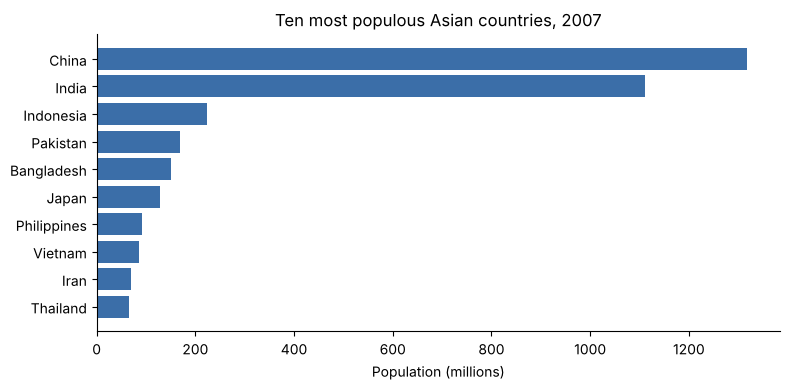

In [9]:
top = asia.nlargest(10, "pop").iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top["country"], top["pop_millions"], color="#3b6ea8")
ax.set_xlabel("Population (millions)")
ax.set_title(f"Ten most populous Asian countries, {year}")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### Pandas - one country's history (Philippines)

year,lifeExp,lifeExp_change,pop_millions,gdpPercap
1952,47.75,+0.00,22.4,"1,273"
1957,51.33,+3.58,26.1,"1,548"
1962,54.76,+7.00,30.3,"1,650"
1967,56.39,+8.64,35.4,"1,814"
1972,58.06,+10.31,40.9,"1,989"
1977,60.06,+12.31,46.9,"2,373"
1982,62.08,+14.33,53.5,"2,603"
1987,64.15,+16.40,60.0,"2,190"
1992,66.46,+18.71,67.2,"2,279"
1997,68.56,+20.81,75.0,"2,537"


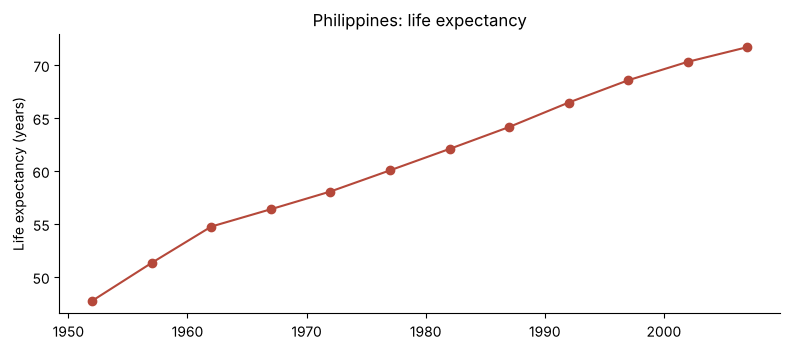

In [10]:
hist = pd.read_csv(OUT / "country_history.csv")
display(hist[["year", "lifeExp", "lifeExp_change", "pop_millions", "gdpPercap"]]
        .style.hide(axis="index").format({"lifeExp": "{:.2f}", "lifeExp_change": "{:+.2f}",
                                           "pop_millions": "{:.1f}", "gdpPercap": "{:,.0f}"}))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(hist["year"], hist["lifeExp"], marker="o", color="#b5483a")
ax.set_ylabel("Life expectancy (years)"); ax.set_title(f"{hist['country'].iloc[0]}: life expectancy")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### NumPy - population index matrix
A matrix of countries by years is built from the canonical table and divided by each country's baseline-year population
using broadcasting, so baseline column reads 100. The program checks the broadcast result against an explicit loop.

,1982,1987,1992,1997,2002,2007
country,,,,,,
Philippines,100.0,112.3,125.7,140.3,155.3,170.4
Indonesia,100.0,110.4,120.5,130.0,137.6,145.8
Thailand,100.0,108.4,116.1,123.3,128.6,133.3


matrix shape: (3, 6) | baseline column all 100: True


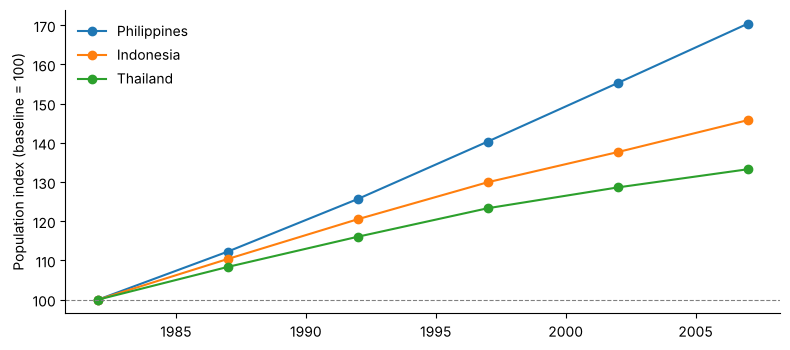

In [11]:
idx = pd.read_csv(OUT / "population_index.csv").set_index("country")
matrix = idx.to_numpy()
display(idx.style.format("{:.1f}"))
print("matrix shape:", matrix.shape, "| baseline column all 100:", bool(np.allclose(matrix[:, 0], 100.0)))
fig, ax = plt.subplots(figsize=(8, 3.6))
for country, row in idx.iterrows():
    ax.plot([int(c) for c in idx.columns], row.values, marker="o", label=country)
ax.axhline(100, color="grey", lw=0.8, ls="--")
ax.set_ylabel("Population index (baseline = 100)"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 6. Export verification
The canonical table is written to CSV, JSON, Parquet and Excel. Each file is then read back, forced through the
canonical schema again. It will be compared by key with what was written. 
Four things are checked per format: row count, values, data types and column order.


In [12]:
checks = pd.read_csv(OUT / "validation_checks.csv", keep_default_na=False)
exp = checks[checks["group"] == "export_failure"].copy()
exp["format"] = exp["check"].str.split("_").str[1]
exp["test"] = exp["check"].str.split("_").str[2]
table = exp.pivot(index="format", columns="test", values="pass").loc[["csv", "json", "parquet", "xlsx"]]
display(table.map(lambda v: "pass" if str(v) == "True" else "FAIL"))
files = pd.DataFrame(summary["exports"])[["file", "bytes", "sha256"]]
files["sha256"] = files["sha256"].str[:16] + "…"
files.style.hide(axis="index").format({"bytes": "{:,}"})

test,columns,dtypes,rows,values
format,,,,
csv,pass,pass,pass,pass
json,pass,pass,pass,pass
parquet,pass,pass,pass,pass
xlsx,pass,pass,pass,pass


file,bytes,sha256
canonical_dataset.csv,"82,132",7724a8821ac5da99…
canonical_dataset.json,"250,658",3f6c934fd38c3e41…
canonical_dataset.parquet,"44,601",42173c1bfd6c5af0…
canonical_dataset.xlsx,"75,527",d61cf930945d3b06…


## 7. All validation checks
Every check carries a group, which is the failure category that is raised if it fails.

In [13]:
checks["passed"] = checks["pass"].astype(str) == "True"
grp = checks.groupby("group")["passed"].agg(checks="size", passed="sum").reset_index()
grp["all pass"] = grp["checks"] == grp["passed"]
display(grp.style.hide(axis="index"))
audit = pd.read_csv(OUT / "audit_log.csv")
print(f"Audit log: {len(audit)} entries covering steps:", ", ".join(dict.fromkeys(audit['step'])))

group,checks,passed,all pass
analysis_failure,17,17,True
count_mismatch,22,22,True
export_failure,16,16,True
format_disagreement,3,3,True


Audit log: 18 entries covering steps: read, validate, deduplicate, compare, analysis, export, publish


## 8. Failure handling
A run publishes nothing unless every step and check passes. All results are written to a staging folder first.
Only a complete, fully-checked run replaces the output folder, and any failure deletes the staging folder and leaves
the output folder. Failures are sorted into twelve categories so the cause can be understood.

In [14]:
cat_table = pd.DataFrame([
    ("config_missing", "config.json does not exist"),
    ("manifest_missing", "the manifest named in the config does not exist"),
    ("input_missing", "an input data file does not exist"),
    ("unsupported_format", "file type is not CSV, Excel, JSON or Parquet (unsupported.txt)"),
    ("integrity_mismatch", "file size or SHA-256 differs from the manifest"),
    ("malformed_file", "file cannot be parsed (broken JSON, wrong sheet name)"),
    ("missing_column", "a required column is absent (missing_column.csv)"),
    ("conflicting_key", "same country and year with different values (conflicting_key.csv)"),
    ("count_mismatch", "row counts do not reconcile or differ from the manifest"),
    ("format_disagreement", "the four formats disagree after recovery"),
    ("analysis_failure", "analysis cannot run or a control total is wrong"),
    ("export_failure", "an export does not reload to the same table"),
], columns=["Category", "Raised when"])
assert tuple(cat_table["Category"]) == tuple(CATEGORIES)
cat_table.style.hide(axis="index")

Category,Raised when
config_missing,config.json does not exist
manifest_missing,the manifest named in the config does not exist
input_missing,an input data file does not exist
unsupported_format,"file type is not CSV, Excel, JSON or Parquet (unsupported.txt)"
integrity_mismatch,file size or SHA-256 differs from the manifest
malformed_file,"file cannot be parsed (broken JSON, wrong sheet name)"
missing_column,a required column is absent (missing_column.csv)
conflicting_key,same country and year with different values (conflicting_key.csv)
count_mismatch,row counts do not reconcile or differ from the manifest
format_disagreement,the four formats disagree after recovery


### Live demonstration with the supplied failure files

In [15]:
def digest(folder):
    return {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
            for p in sorted(folder.rglob("*")) if p.is_file()}

before = digest(OUT)
results = []
for fname in ["conflicting_key.csv", "missing_column.csv", "unsupported.txt", "does_not_exist.csv"]:
    try:
        ProcessingRun("config.json").run_single_file(Path("data") / fname)
        results.append((fname, "SUCCEEDED (unexpected)", ""))
    except ProcessingFailure as f:
        results.append((fname, f.category, f.message[:90]))
demo = pd.DataFrame(results, columns=["Input", "Category", "Message"])
display(demo.style.hide(axis="index"))
print("Output folder unchanged after the four failures:", digest(OUT) == before)
print("Staging folder left behind:", Path("staging").exists())

Input,Category,Message
conflicting_key.csv,conflicting_key,"conflicting key ('Afghanistan', 1952): records 1 and 1705 disagree"
missing_column.csv,missing_column,Missing required canonical column(s): ['pop']
unsupported.txt,unsupported_format,Unsupported file format '.txt' for 'unsupported.txt'.
does_not_exist.csv,input_missing,Input file does not exist: data/does_not_exist.csv


Output folder unchanged after the four failures: True
Staging folder left behind: False


## 9. Testing and reproducibility
The project has 112 automated tests ( python -m unittest discover -s tests -t . ): unit tests for each module, and
end-to-end tests with one test per failure category, each confirming that nothing is published. The suite passes on
pandas 3.0.6 and pandas 2.2.3. The pipeline is also deterministic. Its running it twice produces byte-identical exports.
Changing reporting_year in config.json (or python main.py --year 1997) regenerates the whole analysis.

In [16]:
first = (OUT / "exports" / "canonical_dataset.csv").read_bytes()
ProcessingRun("config.json").run()
print("Two runs give identical exports:", first == (OUT / "exports" / "canonical_dataset.csv").read_bytes())

Two runs give identical exports: True


## Final areas


In [17]:
display(Markdown(
    f"The four files recover **one** dataset of {summary['canonical_rows']:,} rows covering {summary['countries']} countries. "
    f"Each file reconciles exactly (1,712 raw rows = 6 quarantined + 2 duplicates + 1,704 canonical), the four formats agree "
    f"on every key and value, and all {summary['checks_total']} validation checks pass. "
    f"Asia in {year} has {summary[f'asia_{year}_rows']} countries with a total population of "
    f"{summary[f'asia_{year}_population']:,}; the Philippines has {summary[f'philippines_{year}_population']:,}. "
    f"All four exports reload to the table that was written, and every supplied bad input is rejected with a named "
    f"category without publishing anything."))

The four files recover **one** dataset of 1,704 rows covering 142 countries. Each file reconciles exactly (1,712 raw rows = 6 quarantined + 2 duplicates + 1,704 canonical), the four formats agree on every key and value, and all 58 validation checks pass. Asia in 2007 has 33 countries with a total population of 3,811,953,827; the Philippines has 91,077,287. All four exports reload to the table that was written, and every supplied bad input is rejected with a named category without publishing anything.